In [1]:
# import modules/libraries:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
root = Path("/rcp/rcp42/home/esotelo/Research/ScatteringDAS")
sys.path.insert(0, str(root / "py_files"))
import DAS_processing as DASproc
import DAS_model_inversion as DASmi
import DAS_plots as DASplt

from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import AsinhNorm
import pickle

import numpy as np
import jin_pylib
from jin_pylib import Data2D_XT,ProcessUtil
from glob import glob

import scipy
import scipy.signal as scisig
from scipy.integrate import cumulative_trapezoid
from scipy.fft import fft, ifft, fftfreq
from scipy.signal import butter, filtfilt

%matplotlib widget

In [2]:
# medium parameters
vp=4291.584
vs=2407.92
rho=2600

#fracture compliance
ct_true =7e-11
cn_true=0.5*ct_true

#source location
xs=82.0
ys=3700.25882
ts=1.9096

#fiber gauge length
gl=5

In [4]:
#import scattering data
with open("./data/ref_stf_data.pkl", "rb") as f:
    ref_stf_data = pickle.load(f)


#inc_wave
inc_wave=ref_stf_data['stf_data']['stf_trace']
dist_source=ref_stf_data['stf_data']['mean_dist_source']

#Reflected data
ref_data=ref_stf_data['ref_data']

#geometric factor
freqs=inc_wave["freqs"]
alpha=0.5
gfactor=DASmi.geometric_factor_ref(ref_data,freqs,gl,vs,alpha)

#update dictionary with geometric factors
ref_data.update({
    "Gr": gfactor['Gr'],
    "d_factor": gfactor['d_factor'],
    "freqs":gfactor['freqs'],
    "omega": gfactor['omega']
})

all_angles=ref_data['theta_i_deg']
daxis=ref_data['reflection_traces'].daxis

In [6]:
time=inc_wave['time']
t0=np.max(time)/2
f0=100
f1=75
inc_ricker = DASmi.ricker(time, t0, f0)
inc_ricker_inv = DASmi.ricker(time, t0, f1)

In [8]:
inc_ricker.keys()

dict_keys(['trace', 'time', 'fft', 'freqs'])

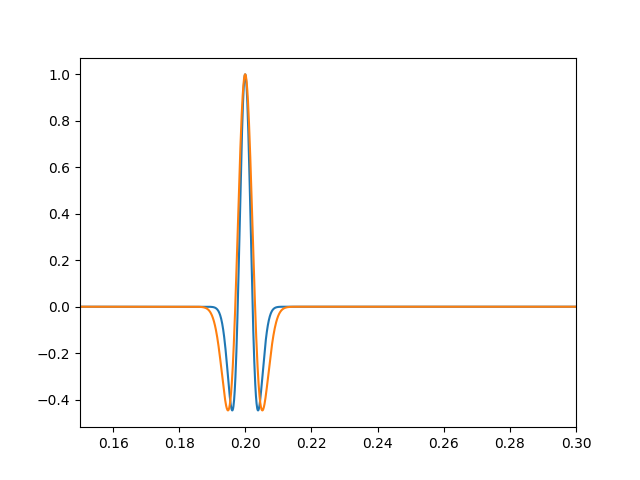

In [16]:
plt.close('all')
plt.figure()
plt.plot(time,inc_ricker['trace'])
plt.plot(time,inc_ricker_inv['trace'])
plt.xlim(0.15,0.30)
plt.show()

In [7]:
# Forward modeling for multiple incident angles
#**********************************************

#define incident angles every 1 degree
init_angle=45
end_angle=5
step_angle=1
angles=np.arange(init_angle,end_angle,-step_angle)

#Choose incident angles from the reflected data
theta_i = ref_data["theta_i_deg"]
idx_test = np.abs(angles[:, None] - theta_i).argmin(axis=1)
idx_test, keep = np.unique(idx_test, return_index=True)
angles_matched = angles[keep]
theta_i_test = theta_i[idx_test]

In [8]:
# Creating the true data
#******************************

#Scalar multiplying the source wavelet is always 1 for the synthetic data
s =1
#Simulated data RT waves
R_batch= DASmi.R_wave_batch(
    ref_data, inc_ricker, idx_test, s, vp, vs, rho, cn_true, ct_true, wave="SS",
)

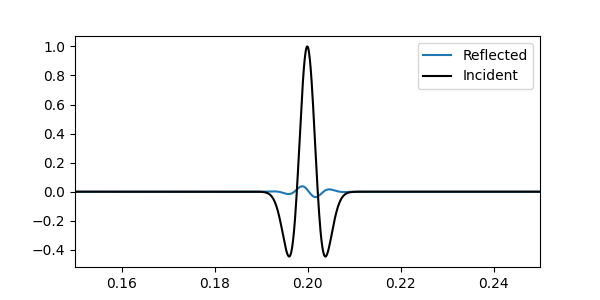

In [9]:
idx=10
plt.close("all")
plt.figure(figsize=(6,3))
plt.plot(R_batch['time'],R_batch['Er_time'][idx],label='Reflected')
plt.plot(R_batch['time'],inc_ricker['trace'],color='k',label='Incident')
plt.xlim(0.15,0.25)
plt.legend()
plt.show()

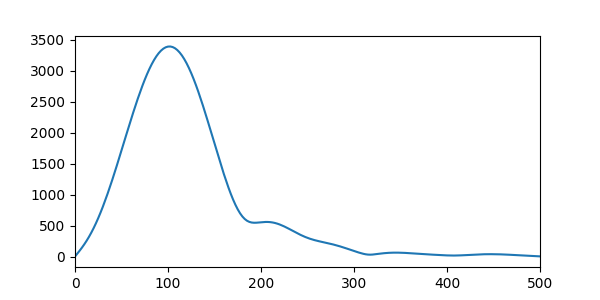

In [10]:
N=len(freqs)
plt.close("all")
plt.figure(figsize=(6,3))
plt.plot(freqs[:N//2],np.abs(inc_wave['fft'])[:N//2])
plt.xlim(0,500)
plt.show()

In [11]:
#inversion: fit R waves using source wavelet

#Estimating the Rwaves using a scaled source wavelet for the forward modeling
nsearch=(50,50)
search_space=[(1e-14,1e-8),(1e-14,1e-8)]

#test1: non-scaled source wavelet (scalar applied to synthetic data)
scalar1 =1

In [12]:
gsR_time1 = DASmi.cnct_search_Rtime(
    R_batch, ref_data, inc_ricker_inv, scalar1,
    vp, vs, rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

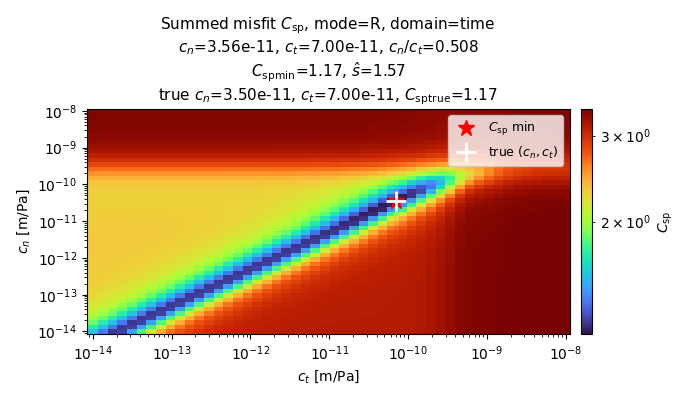

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.56e-11, $c_t$=7.00e-11, $c_n/c_t$=0.508\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=1.17, $\\hat{s}$=1.57\ntrue $c_n$=3.50e-11, $c_t$=7.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=1.17'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [13]:
DASplt.plot_cost_sum(gsR_time1, figsize=(7, 4))

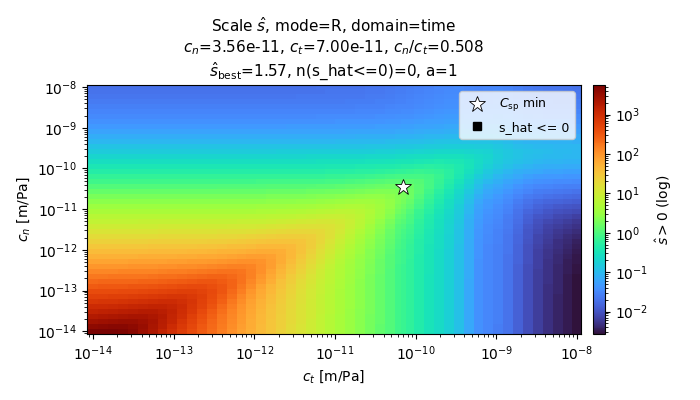

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.56e-11, $c_t$=7.00e-11, $c_n/c_t$=0.508\n$\\hat{s}_{\\mathrm{best}}$=1.57, n(s_hat<=0)=0, a=1'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [14]:
DASplt.plot_s_hat(gsR_time1, figsize=(7, 4))

In [15]:
gsR_time1V2 = DASmi.cnct_search_RtimeV2(
    R_batch, ref_data, inc_ricker_inv, scalar1,
    vp, vs, rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

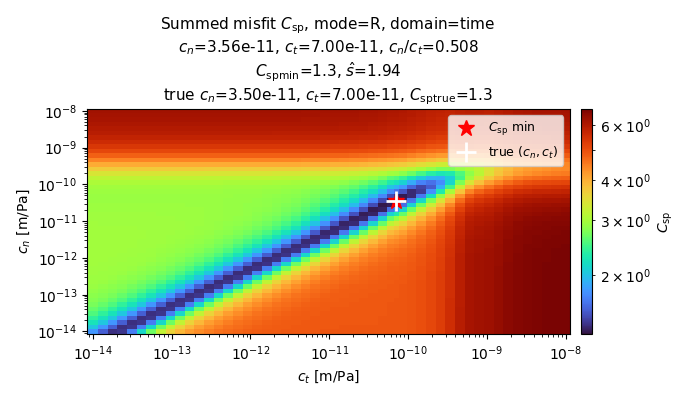

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.56e-11, $c_t$=7.00e-11, $c_n/c_t$=0.508\n$C_{\\mathrm{sp}}$$_{\\mathrm{min}}$=1.3, $\\hat{s}$=1.94\ntrue $c_n$=3.50e-11, $c_t$=7.00e-11, $C_{\\mathrm{sp}}$$_{\\mathrm{true}}$=1.3'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [16]:
DASplt.plot_cost_sum(gsR_time1V2, figsize=(7, 4))


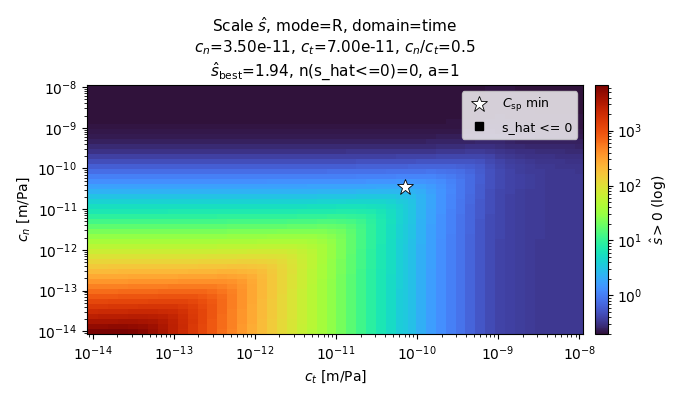

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=1.94, n(s_hat<=0)=0, a=1'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [33]:
DASplt.plot_s_hat(gsR_time1V2, figsize=(7, 4))

In [ ]:
#test2: non-scaled source wavelet (scalar applied to synthetic data)
scalar2 =5
gsR_time2 = DASmi.cnct_search_Rtime(
    R_batch, ref_data, inc_ricker_inv, scalar2,
    vp, vs, rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

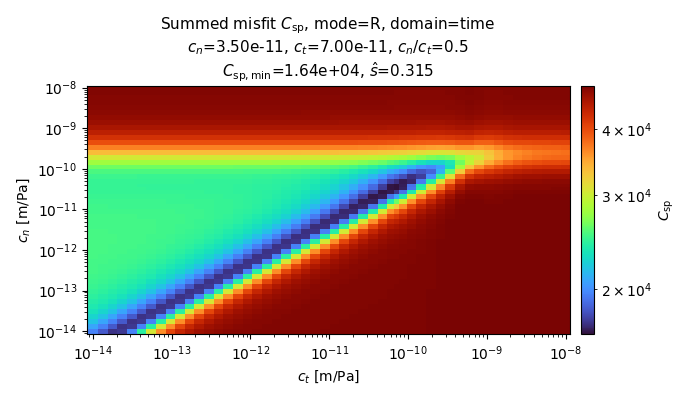

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp},\\mathrm{min}}$=1.64e+04, $\\hat{s}$=0.315'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [25]:
DASplt.plot_cost_sum(gsR_time2, figsize=(7, 4))

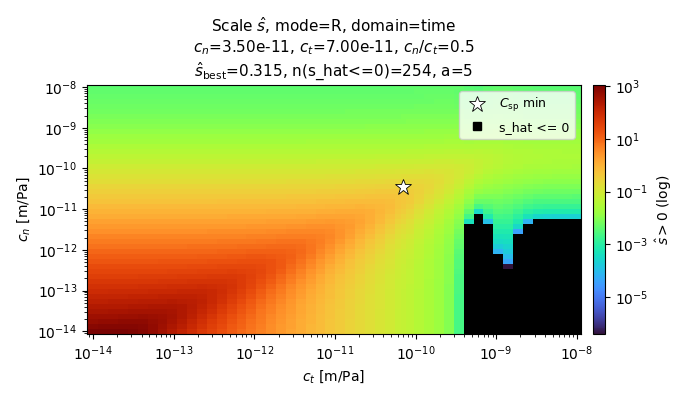

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=0.315, n(s_hat<=0)=254, a=5'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [27]:
DASplt.plot_s_hat(gsR_time2, figsize=(7, 4))

In [34]:
gsR_time2V2 = DASmi.cnct_search_RtimeV2(
    R_batch, ref_data, inc_ricker_inv, scalar2,
    vp, vs, rho,
    search_space,
    nsearch,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

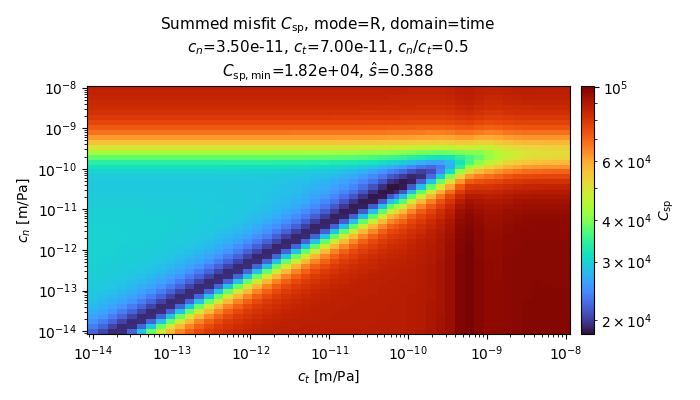

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp},\\mathrm{min}}$=1.82e+04, $\\hat{s}$=0.388'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [35]:
DASplt.plot_cost_sum(gsR_time2V2, figsize=(7, 4))

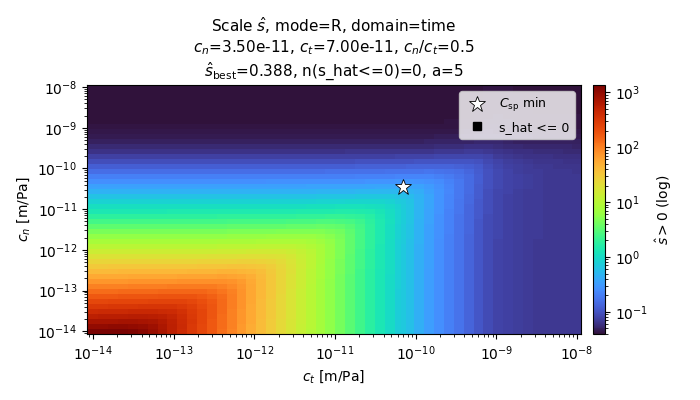

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Scale $\\hat{s}$, mode=R, domain=time\n$c_n$=3.50e-11, $c_t$=7.00e-11, $c_n/c_t$=0.5\n$\\hat{s}_{\\mathrm{best}}$=0.388, n(s_hat<=0)=0, a=5'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n$ [m/Pa]'>)

In [36]:
DASplt.plot_s_hat(gsR_time2V2, figsize=(7, 4))

In [18]:
#Test1:cnct ratio
search_space11=[(0.01,3.0),(1e-14,1e-8)]
nsearch11=(50,50)

gsR_time2_ratio = DASmi.cnct_search_Rtime_ratio(
    R_batch, ref_data, inc_ricker_inv, scalar2,
    vp, vs, rho,
    search_space11,
    nsearch11,
    true_cnct=(cn_true, ct_true),
    wave="SS",
)

NameError: name 'scalar2' is not defined

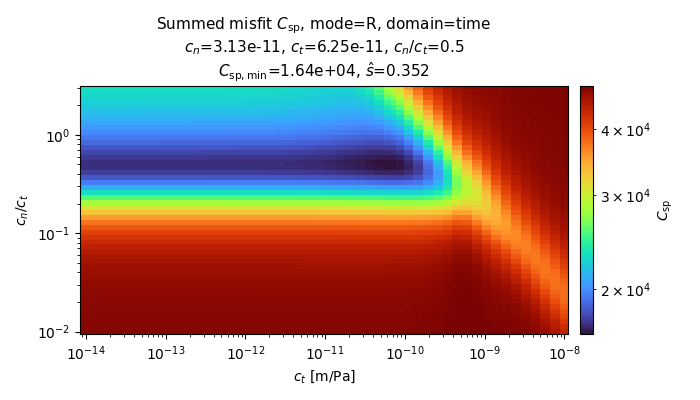

(<Figure size 700x400 with 2 Axes>,
 <Axes: title={'center': 'Summed misfit $C_{\\mathrm{sp}}$, mode=R, domain=time\n$c_n$=3.13e-11, $c_t$=6.25e-11, $c_n/c_t$=0.5\n$C_{\\mathrm{sp},\\mathrm{min}}$=1.64e+04, $\\hat{s}$=0.352'}, xlabel='$c_t$ [m/Pa]', ylabel='$c_n / c_t$'>)

In [38]:
DASplt.plot_cost_sum(gsR_time2_ratio, figsize=(7, 4))